# 02 · Preprocessing & Modeling — Left vs Right Motor Imagery

**Scope (my phase):** config-driven preprocessing → label alignment → CSP+SVM vs EEGNet → comparison → deployable export.

| Step | What happens | Output |
|---|---|---|
| 1 | Load `00_config/preprocessing_config.json` (single source of truth) | `CFG` |
| 2 | Preprocess every raw trial: linear detrend → notch → Butterworth band-pass (zero-phase) → edge trim | `02_preprocessed/X_preprocessed.npy` |
| 3 | Map labels by **ascending numeric file ID** (never alphabetical) | `02_preprocessed/y.npy`, `file_ids.npy` |
| 4 | Consistent leakage-safe split (re-uses EDA `05_splits/split_assignment.csv` when present) | `train / val / test` |
| 5 | Train **CSP + SVM** (grouped-CV tuned) and **EEGNet** (PyTorch) | models |
| 6 | Compare: Balanced Acc · Macro-F1 · ROC-AUC · confusion matrices | `06_reports/model_comparison.*` |
| 7 | Export best classical pipeline → `03_features/csp_svm_baseline.joblib` + loader helper | deployment bundle |

**Facts taken from the EDA notebook (verified in its code, not assumed):** files are `cellula_MI_data_<id>.csv` with columns `Time, FZ, C3, CZ, C4` and 2500 rows; `labels.csv` has one `label` column (`Left`/`Right`) and **more rows than files** — the first N rows pair with the N files sorted by numeric ID; trailing rows are ignored. The code below also accepts `.xlsx` files, in case the data really arrives as Excel.

In [10]:
import os, re, sys, json, time, warnings, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from scipy import signal

import mne
from mne.decoding import CSP
import sklearn
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.metrics import (balanced_accuracy_score, f1_score, roc_auc_score,
                             confusion_matrix, roc_curve, ConfusionMatrixDisplay)

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

warnings.filterwarnings("ignore")
mne.set_log_level("ERROR")

# ---- project root: works from Task7/Notebooks/ or Task7/, override with BCI_ROOT -------------------------
_cwd = Path.cwd().resolve()
ROOT = Path(os.environ["BCI_ROOT"]) if os.environ.get("BCI_ROOT") else (_cwd.parent if _cwd.name.lower() == "notebooks" else _cwd)
RAW_DIR    = ROOT / "raw_data"
LABELS_CSV = ROOT / "labels.csv"
PREP       = ROOT / "bci_prepared"
D = dict(config=PREP/"00_config", pre=PREP/"02_preprocessed", feat=PREP/"03_features",
         labels=PREP/"04_labels", splits=PREP/"05_splits", reports=PREP/"06_reports")
for p in D.values(): p.mkdir(parents=True, exist_ok=True)

FORCE_REPROCESS = os.environ.get("BCI_FORCE_REPROCESS", "0") == "1"   # True = ignore cached X_preprocessed.npy
EEGNET_EPOCHS   = int(os.environ.get("BCI_EEGNET_EPOCHS", "150"))     # upper bound; early stopping applies
print("ROOT :", ROOT)
print("raw  :", RAW_DIR, "| exists:", RAW_DIR.exists())
print(f"mne {mne.__version__} | sklearn {sklearn.__version__} | torch {torch.__version__}")

ROOT : /home/iroh/Documents/task7/Task7
raw  : /home/iroh/Documents/task7/Task7/raw_data | exists: True
mne 1.13.2 | sklearn 1.9.1 | torch 2.15.0+cu132


## 1 · Ingest configuration
Every preprocessing parameter comes from `preprocessing_config.json`. The helper `dig` tolerates the nested layout written by the EDA notebook (`sampling_rate.value_hz`, `notch.hz`, …) as well as flat keys (`sfreq`, `notch_hz`).

In [11]:
cfg_path = D["config"] / "preprocessing_config.json"
assert cfg_path.exists(), f"Missing config: {cfg_path} (run the EDA notebook first)"
RAWCFG = json.loads(cfg_path.read_text())

def dig(cfg, *paths, default=None):
    # first path that resolves wins; a path is 'a.b.c'
    for p in paths:
        cur, ok = cfg, True
        for k in p.split("."):
            if isinstance(cur, dict) and k in cur: cur = cur[k]
            else: ok = False; break
        if ok and cur is not None: return cur
    return default

order_txt = str(dig(RAWCFG, "filter", "filter_order", default="Butterworth order 4"))
_m = re.search(r"order\s*(\d+)", order_txt)

CFG = dict(
    fs          = float(dig(RAWCFG, "sampling_rate.value_hz", "sfreq", "fs_hz", "sampling_rate")),
    bandpass    = tuple(float(v) for v in dig(RAWCFG, "bandpass_hz")),
    notch_hz    = dig(RAWCFG, "notch.hz", "notch_hz", "notch"),
    notch_q     = float(dig(RAWCFG, "notch_q", "notch.q", default=30.0)),
    order       = int(_m.group(1)) if _m else (int(order_txt) if order_txt.isdigit() else 4),
    edge_trim_s = float(dig(RAWCFG, "edge_trim_s", default=0.5)),
    channels    = [c.upper() for c in dig(RAWCFG, "channels", "channel_order", default=["FZ", "C3", "CZ", "C4"])],
    time_col    = dig(RAWCFG, "time_col", default="Time"),
    seed        = int(dig(RAWCFG, "random_state", "seed", "split.seed", default=42)),
    split       = dig(RAWCFG, "split", default={}) or {},
)
if CFG["notch_hz"] is None or isinstance(CFG["notch_hz"], (dict, str)):
    print("WARNING: config has no numeric notch frequency -> using 50 Hz (project brief).")
    CFG["notch_hz"] = 50.0
CFG["notch_hz"] = float(CFG["notch_hz"])
assert 0 < CFG["bandpass"][0] < CFG["bandpass"][1] < CFG["fs"] / 2, "band-pass incompatible with fs"
assert CFG["notch_hz"] < CFG["fs"] / 2, "notch above Nyquist"

SEED = CFG["seed"]
np.random.seed(SEED); torch.manual_seed(SEED)
print(json.dumps({k: v for k, v in CFG.items() if k != "split"}, indent=2))
print("sampling-rate status in config:", dig(RAWCFG, "sampling_rate.status", default="n/a"),
      "(INFERRED = working assumption from EDA, not authoritative)")

{
  "fs": 250.0,
  "bandpass": [
    3.0,
    40.0
  ],
  "notch_hz": 50.0,
  "notch_q": 30.0,
  "order": 4,
  "edge_trim_s": 0.5,
  "channels": [
    "FZ",
    "C3",
    "CZ",
    "C4"
  ],
  "time_col": "Time",
  "seed": 42
}
sampling-rate status in config: INFERRED (INFERRED = working assumption from EDA, not authoritative)


## 2 · Preprocessing function
`PREPROC_SRC` is the **single source of truth** for preprocessing. The notebook `exec`s it for training and also writes it verbatim to `03_features/bci_preprocess.py`, so the Streamlit app applies the identical transform (the roadmap's “keep preprocessing code identical between training and inference”).

Order (as in the EDA): **linear detrend → notch (`iirnotch`, zero-phase) → Butterworth band-pass (SOS, zero-phase) → trim `edge_trim_s` from both ends** (removes filter edge transients). No per-trial z-scoring, re-referencing or event baseline — the EDA documents that units and cue timing are unknown.

In [12]:
PREPROC_SRC = r"""
# bci_preprocess.py  --  generated by 02_Modeling_and_Comparison.ipynb (do not edit by hand)
import re
import numpy as np
import pandas as pd
from pathlib import Path
from scipy import signal


def preprocess_trial(x, fs, bandpass, notch_hz, notch_q=30.0, order=4, edge_trim_s=0.5):
    # x: (n_samples, n_channels) raw -> (n_samples - 2*trim, n_channels) float64
    x = np.asarray(x, dtype=float)
    if x.ndim != 2:
        raise ValueError("expected 2-D (samples, channels), got %s" % (x.shape,))
    if not np.isfinite(x).all():
        raise ValueError("non-finite values (no imputation is performed)")
    lo, hi = bandpass
    y = signal.detrend(x, axis=0, type="linear")
    if notch_hz is not None:
        b, a = signal.iirnotch(notch_hz, notch_q, fs=fs)
        y = signal.filtfilt(b, a, y, axis=0)
    sos = signal.butter(order, [lo, hi], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, y, axis=0)
    k = int(round(edge_trim_s * fs))
    return y[k:len(y) - k] if k > 0 else y


def load_trial_table(path, channels, time_col="Time"):
    # reads .csv or .xlsx and returns (n_samples, n_channels) in the order of `channels`
    path = Path(path)
    df = pd.read_excel(path) if path.suffix.lower() in (".xlsx", ".xls") else pd.read_csv(path)
    cols = {str(c).strip().upper(): c for c in df.columns}
    missing = [c for c in channels if c.upper() not in cols]
    if missing:
        raise ValueError("missing channel columns %s in %s" % (missing, path.name))
    return df[[cols[c.upper()] for c in channels]].to_numpy(dtype=float)


def preprocess_file(path, cfg):
    raw = load_trial_table(path, cfg["channels"], cfg.get("time_col", "Time"))
    y = preprocess_trial(raw, cfg["fs"], cfg["bandpass"], cfg["notch_hz"],
                         cfg.get("notch_q", 30.0), cfg.get("order", 4), cfg["edge_trim_s"])
    return y.T.astype(np.float32)          # (n_channels, n_times)  -- the layout MNE-CSP / EEGNet expect
"""
exec(PREPROC_SRC)

# ---- numeric (not alphabetical) discovery: 1, 2, ..., 10 and never 1, 10, 100, 2 ---------------------------
def discover_files(raw_dir):
    rows = []
    for p in Path(raw_dir).rglob("*"):
        if p.suffix.lower() in (".csv", ".xlsx", ".xls") and p.name.lower() != "labels.csv":
            m = re.search(r"(\d+)(?=\.[^.]+$)", p.name)
            if m: rows.append(dict(file_id=int(m.group(1)), filename=p.name, path=str(p)))
    df = pd.DataFrame(rows).sort_values(["file_id", "filename"]).reset_index(drop=True)
    dup = df.file_id[df.file_id.duplicated()].unique()
    if len(dup): raise ValueError(f"Duplicate numeric IDs make label pairing ambiguous: {dup[:10]}")
    return df

files_df = discover_files(RAW_DIR)
print(f"{len(files_df)} trial files | IDs {files_df.file_id.min()}..{files_df.file_id.max()}")
gaps = sorted(set(range(files_df.file_id.min(), files_df.file_id.max() + 1)) - set(files_df.file_id))
print("gaps in ID sequence:", gaps[:20] if gaps else "none")
print("first 5 after numeric sort:", files_df.filename.head(5).tolist())

2160 trial files | IDs 1..2160
gaps in ID sequence: none
first 5 after numeric sort: ['cellula_MI_data_1.csv', 'cellula_MI_data_2.csv', 'cellula_MI_data_3.csv', 'cellula_MI_data_4.csv', 'cellula_MI_data_5.csv']


## 3 · Run preprocessing on all trials
Failures are **logged, never silent** (reason per file). Trials whose length differs from the modal length are excluded, because a stacked array needs one common length. Results are cached so re-running the notebook is fast (`BCI_FORCE_REPROCESS=1` to recompute).

In [13]:
PCFG = dict(fs=CFG["fs"], bandpass=CFG["bandpass"], notch_hz=CFG["notch_hz"], notch_q=CFG["notch_q"],
            order=CFG["order"], edge_trim_s=CFG["edge_trim_s"], channels=CFG["channels"], time_col=CFG["time_col"])

cache_X, cache_ids = D["pre"] / "X_preprocessed.npy", D["pre"] / "file_ids.npy"
cache_sig = D["pre"] / "preprocess_signature.json"
signature = dict(PCFG, n_files=len(files_df), first=files_df.filename.iloc[0], last=files_df.filename.iloc[-1])
signature = json.loads(json.dumps(signature, default=str))

use_cache = (not FORCE_REPROCESS and cache_X.exists() and cache_ids.exists() and cache_sig.exists()
             and json.loads(cache_sig.read_text()) == signature)
failures = []
if use_cache:
    X_all, ids_all = np.load(cache_X), np.load(cache_ids)
    print("Loaded cached preprocessed array:", X_all.shape)
else:
    t0, out, ok_ids = time.time(), [], []
    for i, r in enumerate(files_df.itertuples(), 1):
        try:
            out.append(preprocess_file(r.path, PCFG)); ok_ids.append(r.file_id)
        except Exception as e:
            failures.append(dict(file_id=r.file_id, filename=r.filename, stage="preprocess", reason=str(e)[:200]))
        if i % 250 == 0: print(f"  {i}/{len(files_df)} ({time.time()-t0:.0f}s)")
    lens = pd.Series([a.shape[1] for a in out])
    T_mode = int(lens.mode().iloc[0])
    keep = [k for k, a in enumerate(out) if a.shape[1] == T_mode]
    for k, a in enumerate(out):
        if a.shape[1] != T_mode:
            failures.append(dict(file_id=ok_ids[k], filename="", stage="length", reason=f"n_times={a.shape[1]} != modal {T_mode}"))
    X_all = np.stack([out[k] for k in keep]).astype(np.float32)
    ids_all = np.array([ok_ids[k] for k in keep], dtype=int)
    np.save(cache_X, X_all); np.save(cache_ids, ids_all); cache_sig.write_text(json.dumps(signature, indent=2))
    pd.DataFrame(failures, columns=["file_id", "filename", "stage", "reason"]).to_csv(D["reports"] / "preprocessing_exclusions.csv", index=False)
    print(f"Done in {time.time()-t0:.0f}s | kept {len(keep)} | excluded {len(failures)}")

n_trials, n_ch, n_times = X_all.shape
print(f"X_all: {X_all.shape} (trials, channels, samples) = {n_times/CFG['fs']:.2f} s per trial after trimming {CFG['edge_trim_s']} s each side")
assert np.isfinite(X_all).all()
assert np.all(np.diff(ids_all) > 0), "IDs must be strictly ascending"

  250/2160 (1s)
  500/2160 (1s)
  750/2160 (2s)
  1000/2160 (2s)
  1250/2160 (3s)
  1500/2160 (3s)
  1750/2160 (4s)
  2000/2160 (4s)
Done in 5s | kept 2160 | excluded 0
X_all: (2160, 4, 2250) (trials, channels, samples) = 9.00 s per trial after trimming 0.5 s each side


## 4 · Map labels to trials (ascending numeric ID)
Rule confirmed in the EDA: the k-th file in numeric order ↔ the k-th row of `labels.csv`; extra trailing label rows are ignored. Pairing is done by **position in the full sorted file list** (before any exclusion), so dropping a bad trial can never shift later labels. Encoding: `Left = 0`, `Right = 1`.

In [14]:
lab = pd.read_csv(LABELS_CSV)
lab_col = "label" if "label" in lab.columns else lab.columns[-1]
lab["_y"] = lab[lab_col].astype(str).str.strip().str.lower().map({"left": 0, "right": 1})
print(f"labels.csv rows: {len(lab)} | files: {len(files_df)} | unmapped label strings: {int(lab._y.isna().sum())}")
assert len(lab) >= len(files_df), "fewer labels than files -> pairing impossible"

# position-based pairing against the FULL numeric-sorted file list
pair = files_df[["file_id", "filename"]].copy()
pair["label_row_1based"] = np.arange(1, len(pair) + 1)
pair["y"] = lab._y.iloc[:len(pair)].to_numpy()
assert pair.y.notna().all(), "invalid/missing label among the paired rows"
if len(lab) > len(files_df): print(f"Ignoring {len(lab)-len(files_df)} trailing label rows (rows {len(files_df)+1}..{len(lab)}).")
if gaps: print("NOTE: ID gaps exist; pairing stays positional as agreed in the EDA.")

# align to the preprocessed array through file_id (robust to any excluded trial)
y_all = pair.set_index("file_id").loc[ids_all, "y"].to_numpy().astype(int)
fn_all = pair.set_index("file_id").loc[ids_all, "filename"].to_numpy()
assert len(y_all) == len(X_all) == len(ids_all)

# spot-check alignment: ids ascending, label row == rank in sorted file list
rank = pd.Series(np.arange(1, len(pair) + 1), index=pair.file_id)
assert np.array_equal(rank.loc[ids_all].to_numpy(), pair.set_index("file_id").loc[ids_all, "label_row_1based"].to_numpy())
print("class balance  Left/Right:", np.bincount(y_all).tolist(), "| P(Right) = %.3f" % y_all.mean())
print(pair.set_index("file_id").loc[ids_all[:3]].assign(y_name=lambda d: d.y.map({0: "Left", 1: "Right"})))

# ---- save arrays ------------------------------------------------------------------------------------------
np.save(D["pre"] / "X_preprocessed.npy", X_all)
np.save(D["pre"] / "y.npy", y_all)
np.save(D["pre"] / "file_ids.npy", ids_all)
pd.DataFrame(dict(file_id=ids_all, filename=fn_all, y=y_all, label=np.where(y_all == 1, "Right", "Left"))).to_csv(D["labels"] / "labels_aligned.csv", index=False)
(D["pre"] / "preprocessed_meta.json").write_text(json.dumps(dict(
    shape=list(X_all.shape), layout="(trials, channels, samples)", channels=CFG["channels"], fs_hz=CFG["fs"],
    bandpass_hz=CFG["bandpass"], notch_hz=CFG["notch_hz"], filter_order=CFG["order"], edge_trim_s=CFG["edge_trim_s"],
    label_encoding={"Left": 0, "Right": 1}, pairing="ascending numeric file ID <-> labels.csv row order (first N rows)"), indent=2))
print("saved ->", D["pre"])

labels.csv rows: 2400 | files: 2160 | unmapped label strings: 0
Ignoring 240 trailing label rows (rows 2161..2400).
class balance  Left/Right: [1082, 1078] | P(Right) = 0.499
                      filename  label_row_1based  y y_name
file_id                                                   
1        cellula_MI_data_1.csv                 1  0   Left
2        cellula_MI_data_2.csv                 2  1  Right
3        cellula_MI_data_3.csv                 3  0   Left
saved -> /home/iroh/Documents/task7/Task7/bci_prepared/02_preprocessed


## 5 · One consistent split for every model
Follows the team rule “same split for every model”. If the EDA notebook already wrote `05_splits/split_assignment.csv` (contiguous file-ID blocks + embargo, no leakage between neighbouring trials) it is used **as-is**; trials in the `EMBARGO` bucket are not used. Otherwise the same blocked + embargo algorithm is reproduced from the config. `block` is also the **group** for cross-validation so CV folds respect the same neighbour-leakage logic.

In [15]:
def make_block_split(file_ids, y, fractions, block_size, embargo, seed, n_tries=300):
    ids = np.asarray(file_ids); block = (ids - ids.min()) // block_size
    ub, inv = np.unique(block, return_inverse=True); sizes = np.bincount(inv); total = len(ids)
    quota = {"test": fractions[2] * total, "val": fractions[1] * total}
    rng = np.random.default_rng(seed); best, best_score = None, np.inf
    for _ in range(n_tries):
        assign = np.empty(len(ub), dtype=object); filled = dict(test=0, val=0)
        for b in rng.permutation(len(ub)):
            if filled["test"] < quota["test"]: assign[b] = "test"; filled["test"] += sizes[b]
            elif filled["val"] < quota["val"]: assign[b] = "val"; filled["val"] += sizes[b]
            else: assign[b] = "train"
        split = assign[inv]
        present = [s for s in ("train", "val", "test") if (split == s).any()]
        score = max(abs(y[split == s].mean() - y.mean()) for s in present)
        if any(len(np.unique(y[split == s])) < 2 for s in present): score += 10
        if score < best_score: best, best_score = split.copy(), score
    sp = best.copy(); prio = {"train": 0, "val": 1, "test": 2}; order = np.argsort(ids); sid, ssp = ids[order], sp[order]
    drop = np.zeros(len(ids), bool)
    for a in range(len(sid)):
        b = a + 1
        while b < len(sid) and sid[b] - sid[a] <= embargo:
            if ssp[a] != ssp[b]: drop[order[a if prio[ssp[a]] < prio[ssp[b]] else b]] = True
            b += 1
    sp[drop] = "EMBARGO"
    return pd.DataFrame({"file_id": ids, "block": block, "split": sp})

split_file = D["splits"] / "split_assignment.csv"
sp_cfg = CFG["split"]
if split_file.exists():
    split_df = pd.read_csv(split_file)[["file_id", "block", "split"]]
    split_src = f"re-used from EDA: {split_file.name}"
else:
    bs = int(sp_cfg.get("block_size") or 20); em = int(sp_cfg.get("embargo") or 5)
    fr = sp_cfg.get("fractions") or (0.70, 0.15, 0.15)
    split_df = make_block_split(ids_all, y_all, fr, bs, em, SEED)
    split_df.to_csv(D["splits"] / "split_assignment.csv", index=False)
    split_src = f"generated here (block={bs}, embargo={em}, fractions={tuple(fr)}, seed={SEED})"

sp = pd.DataFrame(dict(file_id=ids_all, y=y_all)).merge(split_df, on="file_id", how="left")
sp["split"] = sp["split"].fillna("EMBARGO")                    # a trial not present in the split file is not used
sp["pos"] = np.arange(len(sp))
print("split source:", split_src)
print(sp.groupby("split").agg(n=("y", "size"), right_share=("y", "mean")).round(3))

idx = {s: sp.loc[sp.split == s, "pos"].to_numpy() for s in ("train", "val", "test")}
grp = sp["block"].to_numpy()
Xtr, ytr, Xva, yva, Xte, yte = (X_all[idx["train"]], y_all[idx["train"]], X_all[idx["val"]], y_all[idx["val"]],
                                X_all[idx["test"]], y_all[idx["test"]])
for n, a in zip(("train", "val", "test"), (ytr, yva, yte)):
    assert len(np.unique(a)) == 2, f"{n} split lacks a class"
# disjointness check (ids)
sets = {s: set(ids_all[idx[s]]) for s in idx}
assert not (sets["train"] & sets["val"]) and not (sets["train"] & sets["test"]) and not (sets["val"] & sets["test"])
print("shapes:", Xtr.shape, Xva.shape, Xte.shape)

split source: re-used from EDA: split_assignment.csv
            n  right_share
split                     
EMBARGO   275        0.498
test      352        0.500
train    1203        0.499
val       330        0.500
shapes: (1203, 4, 2250) (330, 4, 2250) (352, 4, 2250)


## 6 · Evaluation helper
Metrics reported for every model on the **same held-out test set**: Balanced Accuracy, Macro-F1, ROC-AUC (from probability of *Right*), and the confusion matrix (rows = true, columns = predicted; order Left, Right).

In [16]:
LABEL_NAMES = ["Left", "Right"]
RESULTS, PROBS = {}, {}

def evaluate(name, y_true, proba_right, extra=None):
    pred = (proba_right >= 0.5).astype(int)
    res = dict(balanced_acc=balanced_accuracy_score(y_true, pred),
               macro_f1=f1_score(y_true, pred, average="macro"),
               roc_auc=roc_auc_score(y_true, proba_right),
               cm=confusion_matrix(y_true, pred, labels=[0, 1]))
    if extra: res.update(extra)
    RESULTS[name] = res; PROBS[name] = proba_right
    print(f"{name:<12} BalAcc={res['balanced_acc']:.4f}  MacroF1={res['macro_f1']:.4f}  AUC={res['roc_auc']:.4f}")
    return res

## 7 · Model A — CSP + SVM (classical baseline)
`CSP` (MNE; log-variance features) → `StandardScaler` → `SVC`. Hyper-parameters (number of CSP components, covariance regularisation, kernel, C, gamma) are tuned with **`GroupKFold` over contiguous blocks** on train + val — the test set is untouched. The final model is refit on train + val with `probability=True` (Platt scaling) so the app can show a confidence. With only 4 channels the CSP has at most 4 components.

In [17]:
Xtv = np.concatenate([Xtr, Xva]).astype(np.float64); ytv = np.concatenate([ytr, yva]); gtv = np.concatenate([grp[idx["train"]], grp[idx["val"]]])

def make_csp_svm(probability=False):
    return Pipeline([("csp", CSP(n_components=4, reg=None, log=True, norm_trace=False)),
                     ("scale", StandardScaler()),
                     ("svm", SVC(probability=probability, random_state=SEED))])

param_grid = [
    dict(csp__n_components=[2, 4], csp__reg=[None, "ledoit_wolf"], svm__kernel=["linear"], svm__C=[0.1, 1, 10]),
    dict(csp__n_components=[2, 4], csp__reg=[None, "ledoit_wolf"], svm__kernel=["rbf"], svm__C=[0.1, 1, 10, 100], svm__gamma=["scale", 0.1, 0.01]),
]
n_splits = min(5, len(np.unique(gtv)))
gs = GridSearchCV(make_csp_svm(False), param_grid, scoring="balanced_accuracy",
                  cv=GroupKFold(n_splits=n_splits), n_jobs=1, refit=False, verbose=0)
t0 = time.time(); gs.fit(Xtv, ytv, groups=gtv)
print(f"grid search {time.time()-t0:.0f}s | best grouped-CV balanced acc = {gs.best_score_:.4f}")
print("best params:", gs.best_params_)
cv_table = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")[["params", "mean_test_score", "std_test_score"]].head(8)
display(cv_table)

csp_svm = make_csp_svm(probability=True).set_params(**gs.best_params_).fit(Xtv, ytv)
p_csp = csp_svm.predict_proba(Xte.astype(np.float64))[:, 1]
evaluate("CSP+SVM", yte, p_csp, extra=dict(cv_balanced_acc=gs.best_score_, params=gs.best_params_))

grid search 205s | best grouped-CV balanced acc = 0.5029
best params: {'csp__n_components': 2, 'csp__reg': None, 'svm__C': 1, 'svm__kernel': 'linear'}


,params,mean_test_score,std_test_score
1,"{'csp__n_components': 2, 'csp__reg': None, 'sv...",0.502882,0.018164
4,"{'csp__n_components': 2, 'csp__reg': 'ledoit_w...",0.502882,0.018164
5,"{'csp__n_components': 2, 'csp__reg': 'ledoit_w...",0.502053,0.016986
2,"{'csp__n_components': 2, 'csp__reg': None, 'sv...",0.502053,0.016986
14,"{'csp__n_components': 2, 'csp__reg': None, 'sv...",0.500000,0.000000
26,"{'csp__n_components': 2, 'csp__reg': 'ledoit_w...",0.500000,0.000000
50,"{'csp__n_components': 4, 'csp__reg': 'ledoit_w...",0.500000,0.000000
38,"{'csp__n_components': 4, 'csp__reg': None, 'sv...",0.500000,0.000000


CSP+SVM      BalAcc=0.5312  MacroF1=0.5090  AUC=0.5425


{'balanced_acc': 0.53125,
 'macro_f1': 0.5089576340686005,
 'roc_auc': 0.542500645661157,
 'cm': array([[131,  45],
        [120,  56]]),
 'cv_balanced_acc': np.float64(0.5028823912872137),
 'params': {'csp__n_components': 2,
  'csp__reg': None,
  'svm__C': 1,
  'svm__kernel': 'linear'}}

## 8 · Model B — EEGNet (PyTorch)
Compact EEGNet-8,2 (Lawhern et al. 2018): temporal conv → depthwise spatial conv → separable conv → linear head, ≈2.6 k parameters for 4 channels — appropriate for ~2000 trials. If `braindecode` is installed it is used; otherwise an equivalent native PyTorch implementation is used. Input is scaled by the **train-set per-channel standard deviation** (the EDA found amplitude units unknown/heavy-tailed, so a train-only scale is the safe choice). Early stopping watches **validation** balanced accuracy / loss; the test set is used once at the end.

  ep   1 | train 0.7142 | val loss 0.6919 | val BalAcc 0.5212
  ep  10 | train 0.6831 | val loss 0.6924 | val BalAcc 0.5000
  ep  20 | train 0.6786 | val loss 0.7043 | val BalAcc 0.5061
  ep  30 | train 0.6702 | val loss 0.7167 | val BalAcc 0.4939
  early stop at epoch 39
braindecode.EEGNet | params = 3,410 | 7s | best val BalAcc = 0.5424
EEGNet       BalAcc=0.5284  MacroF1=0.5254  AUC=0.5134


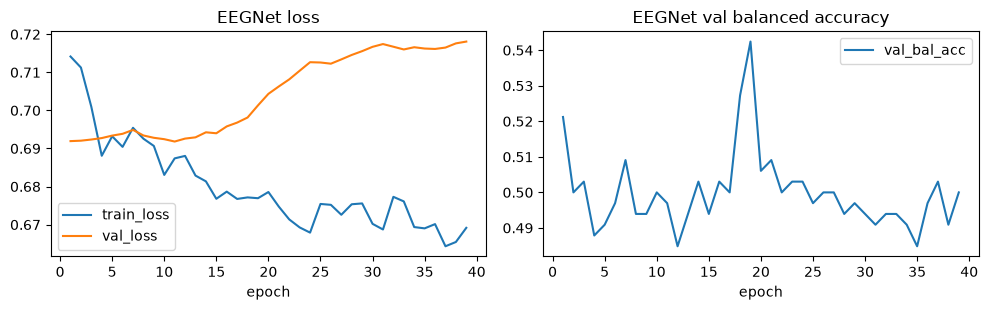

In [18]:
class EEGNetNative(nn.Module):
    # EEGNet-8,2 for input (B, 1, C, T)
    def __init__(self, n_chans, n_times, n_out=2, F1=8, D=2, F2=16, kern=None, dropout=0.5, fs=250):
        super().__init__()
        kern = kern or int(fs // 2)
        self.b1 = nn.Sequential(
            nn.Conv2d(1, F1, (1, kern), padding=(0, kern // 2), bias=False), nn.BatchNorm2d(F1),
            nn.Conv2d(F1, F1 * D, (n_chans, 1), groups=F1, bias=False), nn.BatchNorm2d(F1 * D),
            nn.ELU(), nn.AvgPool2d((1, 4)), nn.Dropout(dropout))
        self.b2 = nn.Sequential(
            nn.Conv2d(F1 * D, F1 * D, (1, 16), padding=(0, 8), groups=F1 * D, bias=False),
            nn.Conv2d(F1 * D, F2, 1, bias=False), nn.BatchNorm2d(F2),
            nn.ELU(), nn.AvgPool2d((1, 8)), nn.Dropout(dropout))
        with torch.no_grad(): n_feat = self.b2(self.b1(torch.zeros(1, 1, n_chans, n_times))).numel()
        self.head = nn.Linear(n_feat, n_out)
    def forward(self, x):
        if x.dim() == 3: x = x.unsqueeze(1)
        return self.head(self.b2(self.b1(x)).flatten(1))

def build_eegnet(n_chans, n_times, fs):
    try:                                           # preferred: braindecode reference implementation
        import braindecode.models as bdm
        cls = getattr(bdm, "EEGNet", None) or getattr(bdm, "EEGNetv4")
        try:    m = cls(n_chans=n_chans, n_outputs=2, n_times=n_times, sfreq=fs)
        except TypeError: m = cls(n_chans=n_chans, n_outputs=2, n_times=n_times)
        return m, "braindecode." + cls.__name__
    except Exception:
        return EEGNetNative(n_chans, n_times, fs=int(fs)), "native PyTorch EEGNet-8,2"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
ch_std = Xtr.std(axis=(0, 2), keepdims=True).astype(np.float32) + 1e-8          # (1, C, 1), train only
scale = lambda a: torch.from_numpy((a / ch_std).astype(np.float32))

def predict_proba_torch(model, X, bs=128):
    model.eval(); out = []
    with torch.no_grad():
        for i in range(0, len(X), bs):
            xb = scale(X[i:i + bs]).to(DEVICE)
            out.append(torch.softmax(model(xb).reshape(len(xb), -1), 1)[:, 1].cpu().numpy())
    return np.concatenate(out)

def train_eegnet(Xtr, ytr, Xva, yva, epochs=EEGNET_EPOCHS, patience=20, lr=1e-3, bs=64, seed=SEED):
    torch.manual_seed(seed); np.random.seed(seed)
    model, impl = build_eegnet(Xtr.shape[1], Xtr.shape[2], CFG["fs"]); model.to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-2)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=7)
    lossf = nn.CrossEntropyLoss()
    gen = torch.Generator().manual_seed(seed)
    dl = DataLoader(TensorDataset(scale(Xtr), torch.from_numpy(ytr).long()), batch_size=bs, shuffle=True, generator=gen)
    best, best_state, wait, hist = (-np.inf, np.inf), None, 0, []
    for ep in range(1, epochs + 1):
        model.train(); tl = 0
        for xb, yb in dl:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            # light augmentation: random circular time shift (+-0.2 s) and small gaussian noise
            sh = int(np.random.randint(-int(0.2 * CFG["fs"]), int(0.2 * CFG["fs"]) + 1)); xb = torch.roll(xb, sh, dims=-1)
            xb = xb + 0.05 * torch.randn_like(xb)
            opt.zero_grad(); loss = lossf(model(xb).reshape(len(xb), -1), yb); loss.backward(); opt.step(); tl += loss.item() * len(xb)
        pv = predict_proba_torch(model, Xva)
        vl = float(-np.mean(np.log(np.clip(np.where(yva == 1, pv, 1 - pv), 1e-7, 1))))
        vb = balanced_accuracy_score(yva, (pv >= .5).astype(int)); sched.step(vl)
        hist.append(dict(epoch=ep, train_loss=tl / len(Xtr), val_loss=vl, val_bal_acc=vb))
        if (vb, -vl) > (best[0], -best[1]):
            best, wait = (vb, vl), 0; best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        else:
            wait += 1
        if ep % 10 == 0 or ep == 1: print(f"  ep {ep:3d} | train {tl/len(Xtr):.4f} | val loss {vl:.4f} | val BalAcc {vb:.4f}")
        if wait >= patience: print(f"  early stop at epoch {ep}"); break
    model.load_state_dict(best_state)
    return model, impl, pd.DataFrame(hist), best

t0 = time.time()
eegnet, EEGNET_IMPL, hist, best_val = train_eegnet(Xtr, ytr, Xva, yva)
print(f"{EEGNET_IMPL} | params = {sum(p.numel() for p in eegnet.parameters()):,} | {time.time()-t0:.0f}s | best val BalAcc = {best_val[0]:.4f}")
p_eeg = predict_proba_torch(eegnet, Xte)
evaluate("EEGNet", yte, p_eeg, extra=dict(val_balanced_acc=best_val[0], impl=EEGNET_IMPL))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
hist.plot(x="epoch", y=["train_loss", "val_loss"], ax=ax[0], title="EEGNet loss"); hist.plot(x="epoch", y="val_bal_acc", ax=ax[1], title="EEGNet val balanced accuracy")
plt.tight_layout(); plt.show()

## 9 · Comparison table, confusion matrices, ROC

,Balanced Accuracy,Macro F1,ROC-AUC,Confusion [[TN FP][FN TP]],n_test
CSP+SVM,0.5312,0.5090,0.5425,"[[131, 45], [120, 56]]",352
EEGNet,0.5284,0.5254,0.5134,"[[107, 69], [97, 79]]",352


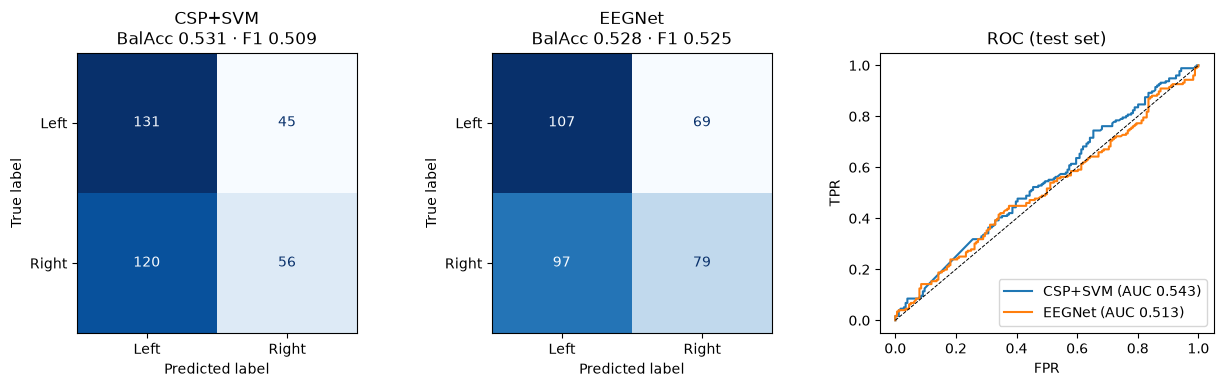

Chance level is 0.50 for Balanced Accuracy / ROC-AUC. With a test set of 352 trials, a 95% binomial interval around 0.5 is about +-0.052; differences smaller than that are not meaningful.
Best on test balanced accuracy: CSP+SVM


In [19]:
table = pd.DataFrame({n: {"Balanced Accuracy": r["balanced_acc"], "Macro F1": r["macro_f1"], "ROC-AUC": r["roc_auc"],
                          "Confusion [[TN FP][FN TP]]": r["cm"].tolist()} for n, r in RESULTS.items()}).T
table["n_test"] = len(yte)
display(table.style.format({"Balanced Accuracy": "{:.4f}", "Macro F1": "{:.4f}", "ROC-AUC": "{:.4f}"}))
table.to_csv(D["reports"] / "model_comparison.csv")

fig, axes = plt.subplots(1, len(RESULTS) + 1, figsize=(4.2 * (len(RESULTS) + 1), 3.9))
for ax, (n, r) in zip(axes, RESULTS.items()):
    ConfusionMatrixDisplay(r["cm"], display_labels=LABEL_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(f"{n}\nBalAcc {r['balanced_acc']:.3f} · F1 {r['macro_f1']:.3f}")
for n, p in PROBS.items():
    fpr, tpr, _ = roc_curve(yte, p); axes[-1].plot(fpr, tpr, label=f"{n} (AUC {RESULTS[n]['roc_auc']:.3f})")
axes[-1].plot([0, 1], [0, 1], "k--", lw=.7); axes[-1].set(title="ROC (test set)", xlabel="FPR", ylabel="TPR"); axes[-1].legend(loc="lower right")
plt.tight_layout(); plt.savefig(D["reports"] / "model_comparison.png", dpi=150); plt.show()

chance_note = ("Chance level is 0.50 for Balanced Accuracy / ROC-AUC. With a test set of "
               f"{len(yte)} trials, a 95% binomial interval around 0.5 is about +-{1.96*0.5/np.sqrt(len(yte)):.3f}; "
               "differences smaller than that are not meaningful.")
print(chance_note)
winner = max(RESULTS, key=lambda k: RESULTS[k]["balanced_acc"])
print("Best on test balanced accuracy:", winner)

## 10 · Export for deployment
Saved to `03_features/`:

| File | Content |
|---|---|
| `csp_svm_baseline.joblib` | fitted sklearn `Pipeline(CSP → StandardScaler → SVC(probability=True))` — input **preprocessed** epochs `(n, 4, 2000)`, output `predict_proba` → `[P(Left), P(Right)]` |
| `bci_preprocess.py` | the exact preprocessing code used for training (`preprocess_file`, `preprocess_trial`) |
| `csp_svm_baseline_meta.json` | channel order, fs, band-pass, notch, trim, expected input shape, label map, version info, test metrics |
| `eegnet.pt` + `eegnet_meta.json` | EEGNet weights / scaling (optional, for comparison demos) |

The pipeline is exported as a plain sklearn object (no custom classes) — the Streamlit side needs `mne`, `scikit-learn`, `scipy`, `joblib` installed with the versions listed in the meta file.

In [20]:
JOBLIB_PATH = D["feat"] / "csp_svm_baseline.joblib"
joblib.dump(csp_svm, JOBLIB_PATH, compress=3)
(D["feat"] / "bci_preprocess.py").write_text(PREPROC_SRC.lstrip("\n"))

meta = dict(
    model="CSP + StandardScaler + SVC(probability=True)", best_params={k: (None if v is None else v) for k, v in gs.best_params_.items()},
    input=dict(layout="(n_trials, n_channels, n_times) float64/float32 AFTER bci_preprocess.preprocess_file", n_channels=n_ch, n_times=n_times, channels=CFG["channels"]),
    preprocessing=dict(fs_hz=CFG["fs"], bandpass_hz=list(CFG["bandpass"]), notch_hz=CFG["notch_hz"], notch_q=CFG["notch_q"],
                       filter_order=CFG["order"], edge_trim_s=CFG["edge_trim_s"], detrend="linear",
                       raw_rows_expected=int(round(n_times + 2 * CFG["edge_trim_s"] * CFG["fs"]))),
    classes={"0": "Left", "1": "Right"}, predict_proba_columns=["P(Left)", "P(Right)"],
    test_metrics=dict(balanced_accuracy=RESULTS["CSP+SVM"]["balanced_acc"], macro_f1=RESULTS["CSP+SVM"]["macro_f1"],
                      roc_auc=RESULTS["CSP+SVM"]["roc_auc"], confusion_matrix=RESULTS["CSP+SVM"]["cm"].tolist(),
                      grouped_cv_balanced_accuracy=float(gs.best_score_), n_test=int(len(yte))),
    trained_on=dict(n_trials=int(len(ytv)), splits="train+val", split_source=split_src),
    versions=dict(python=sys.version.split()[0], sklearn=sklearn.__version__, mne=mne.__version__, numpy=np.__version__,
                  scipy=__import__("scipy").__version__, joblib=joblib.__version__),
    caveat="sampling rate is an INFERRED working value from the EDA; confirm with the data owner",
)
(D["feat"] / "csp_svm_baseline_meta.json").write_text(json.dumps(meta, indent=2, default=str))

torch.save(eegnet.state_dict(), D["feat"] / "eegnet.pt")
(D["feat"] / "eegnet_meta.json").write_text(json.dumps(dict(
    impl=EEGNET_IMPL, n_chans=n_ch, n_times=n_times, fs=CFG["fs"], channel_std=ch_std.reshape(-1).tolist(),
    scaling="x / channel_std (train-only)", classes={"0": "Left", "1": "Right"},
    test_metrics=dict(balanced_accuracy=RESULTS["EEGNet"]["balanced_acc"], macro_f1=RESULTS["EEGNet"]["macro_f1"], roc_auc=RESULTS["EEGNet"]["roc_auc"])), indent=2))

# ---- round-trip test exactly as the Streamlit app would do it -------------------------------------------------
import importlib.util
spec = importlib.util.spec_from_file_location("bci_preprocess", D["feat"] / "bci_preprocess.py"); bp = importlib.util.module_from_spec(spec); spec.loader.exec_module(bp)
loaded = joblib.load(JOBLIB_PATH); m = json.loads((D["feat"] / "csp_svm_baseline_meta.json").read_text())
pc = dict(fs=m["preprocessing"]["fs_hz"], bandpass=tuple(m["preprocessing"]["bandpass_hz"]), notch_hz=m["preprocessing"]["notch_hz"],
          notch_q=m["preprocessing"]["notch_q"], order=m["preprocessing"]["filter_order"], edge_trim_s=m["preprocessing"]["edge_trim_s"], channels=m["input"]["channels"])
test_files = [files_df.set_index("file_id").loc[i, "path"] for i in ids_all[idx["test"]][:5]]
E = np.stack([bp.preprocess_file(p, pc) for p in test_files])
P = loaded.predict_proba(E.astype(np.float64))
assert np.allclose(P[:, 1], p_csp[:5], atol=1e-6), "reloaded model disagrees with in-notebook model"
print("round-trip OK. Example (file -> P(Left), P(Right), true):")
for p, pr, t in zip(test_files, P, yte[:5]): print(f"  {Path(p).name}: {pr.round(3)}  true={LABEL_NAMES[t]}")

print("\nStreamlit usage:\n"
      "    import sys, json, joblib; sys.path.append('bci_prepared/03_features')\n"
      "    import bci_preprocess as bp\n"
      "    meta = json.load(open('bci_prepared/03_features/csp_svm_baseline_meta.json'))\n"
      "    model = joblib.load('bci_prepared/03_features/csp_svm_baseline.joblib')\n"
      "    epoch = bp.preprocess_file(uploaded_path, cfg)[None]   # cfg built from meta['preprocessing'] + meta['input']['channels']\n"
      "    p_right = model.predict_proba(epoch.astype('float64'))[0, 1]")
print("\nFiles in", D["feat"], ":", sorted(p.name for p in D["feat"].iterdir()))

round-trip OK. Example (file -> P(Left), P(Right), true):
  cellula_MI_data_1.csv: [0.484 0.516]  true=Left
  cellula_MI_data_2.csv: [0.508 0.492]  true=Right
  cellula_MI_data_3.csv: [0.494 0.506]  true=Left
  cellula_MI_data_4.csv: [0.5 0.5]  true=Left
  cellula_MI_data_5.csv: [0.5 0.5]  true=Left

Streamlit usage:
    import sys, json, joblib; sys.path.append('bci_prepared/03_features')
    import bci_preprocess as bp
    meta = json.load(open('bci_prepared/03_features/csp_svm_baseline_meta.json'))
    model = joblib.load('bci_prepared/03_features/csp_svm_baseline.joblib')
    epoch = bp.preprocess_file(uploaded_path, cfg)[None]   # cfg built from meta['preprocessing'] + meta['input']['channels']
    p_right = model.predict_proba(epoch.astype('float64'))[0, 1]

Files in /home/iroh/Documents/task7/Task7/bci_prepared/03_features : ['__pycache__', 'bci_preprocess.py', 'csp_svm_baseline.joblib', 'csp_svm_baseline_meta.json', 'eegnet.pt', 'eegnet_meta.json', 'feature_metadata.csv', 'feat

## 11 · Notes for the team
* **Trust the numbers only as far as the split allows.** No subject/session IDs exist, so blocked + embargo splitting is a conservative proxy; generalisation to a *new subject* is not measured here.
* The sampling rate (250 Hz) is **inferred** from timestamps in the EDA (status in the config). CSP/EEGNet depend on it only through the filter design.
* EEGNet's selection uses the validation set only; CSP+SVM's hyper-parameters use grouped CV on train+val; both are scored once on the identical test trials.
* Next options if accuracies are near chance: filter-bank CSP (8–30 Hz sub-bands), Riemannian tangent-space + LR, or longer/overlapping sliding windows — all are drop-in replacements in section 7.